#### LAB 08 — Fine-tuning và đánh giá pretrained Transformer

 

In [5]:
import sys, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
LAB_DIR = Path.cwd() / 'lab8' if (Path.cwd() / 'lab8' / 'pretrained_classification.py').is_file() else Path.cwd()
sys.path.insert(0, str(LAB_DIR.resolve()))
import pretrained_classification as pc
import importlib
importlib.reload(pc)
pc.configure()
tokenizer = pc.load_tokenizer()
experiment = pc.LabExperiment()
 

#### 13. Core Implementation — Classification Head

Pipeline:
Input text -> Tokenizer -> Input IDs -> Pretrained Transformer -> Contextual representations -> [CLS] representation -> Linear layer -> Class logits -> Softmax -> Prediction.




In [6]:
import inspect
print(inspect.getsource(pc.PretrainedSentimentClassifier))

class PretrainedSentimentClassifier(nn.Module):
    """BERT encoder + [CLS] + classification head cho sentiment.

    frozen/finetuned dùng encoder pretrained; scratch khởi tạo encoder ngẫu nhiên.
    forward trả class logits; predict_text áp dụng softmax và chọn nhãn.
    """
    def __init__(self, mode='finetuned'):
        super().__init__()
        if mode not in ('scratch', 'frozen', 'finetuned'):
            raise ValueError('mode: scratch, frozen hoặc finetuned')
        self.mode = mode
        config = BertConfig.from_pretrained(MODEL_DIR, local_files_only=True)
        config._attn_implementation = 'eager'
        # Transformer encoder: Input IDs -> Contextual representations.
        if mode == 'scratch':
            self.encoder = BertModel(config, add_pooling_layer=False)
        else:
            self.encoder = BertModel.from_pretrained(MODEL_DIR, config=config, add_pooling_layer=False,
                                                      local_files_only=True)
        #

#### 14. Experiment 1 — Pretrained vs From Scratch

Dùng IMDb giống LAB 07: clean `<br />` và khoảng trắng, bỏ 422 trùng sau clean, còn 49.578 review; split stratified 70/15/15 seed 42, lấy 10.000 train, 2.000 validation, 2.000 test theo cùng chỉ số. Không chia lại test theo từng experiment.

Cột `Training time` trong các bảng được tính bằng giây.


In [7]:
scratch = experiment.run('scratch')
finetuned = experiment.run('finetuned')
comparison = pd.DataFrame([scratch['row'], finetuned['row']])
comparison_table = comparison.assign(Model=comparison['Mode'].map({
    'scratch': 'Transformer from scratch', 'finetuned': 'Pretrained Transformer'
}))[['Model', 'Accuracy', 'F1', 'Training time (s)', 'Parameters']].rename(columns={
    'Training time (s)': 'Training time', 'Parameters': '# Parameters'
})
display(comparison_table)

**1. Representation khác nhau như thế nào?** 

Scratch bắt đầu từ encoder random, phải học đặc trưng và nhãn trên IMDb. Fine-tuned bắt đầu từ representation pretrained rồi điều chỉnh theo sentiment; cả hai dùng contextual [CLS], cùng kiến trúc và 4,369,666 tham số.

**2. Training data cần thiết khác nhau thế nào?** 

Pretraining cung cấp thông tin học từ corpus ngoài downstream, nên có thể giảm nhu cầu nhãn IMDb. Mức giảm nhu cầu dữ liệu được xem xét qua hai đường cong ở mục 16.

**3. Chi phí tính toán khác nhau thế nào?** 

Scratch mất 143.78s, fine-tuning mất 150.26s cho 3 epochs. Cùng kiến trúc nên chi phí downstream mỗi bước gần nhau; chênh lệch thời gian thực còn do môi trường thực thi. Chi phí pretraining không nằm trong đồng hồ này, không phải bằng 0.

**4. Có phù hợp Prediction 1 không?** 

Accuracy/F1 scratch = 0.8245/0.8234, fine-tuned = 0.8180/0.8162. Kết quả chưa hỗ trợ dự đoán pretrained tốt hơn theo F1 trong cấu hình này. Chỉ so cùng 3 epochs, chưa chứng minh scratch không thể cải thiện nếu được tối ưu hoặc train lâu hơn; cũng không chứng minh model hiểu mọi ngôn ngữ/domain.

#### 15. Experiment 2 — Feature Extraction vs Fine-Tuning

Train head với frozen encoder trên đúng 10.000 review và cùng lịch tối ưu. Dùng lại run fine-tuning mục 14. Frozen vẫn chạy forward encoder để tạo contextual representation; chỉ bỏ backward/update của encoder, không bỏ tính toán encoder.

In [8]:
frozen = experiment.run('frozen')
frozen_table = pd.DataFrame([frozen['row'], finetuned['row']])
frozen_table['Encoder trainable?'] = frozen_table['Mode'].map({'frozen': 'No', 'finetuned': 'Yes'})
frozen_table = frozen_table.assign(Mode=frozen_table['Mode'].map({
    'frozen': 'Frozen', 'finetuned': 'Fine-tuning'
}))[['Mode', 'Encoder trainable?', 'Accuracy', 'F1', 'Training time (s)']].rename(columns={
    'Training time (s)': 'Training time'
})
display(frozen_table)

**Vì sao frozen encoder vẫn classification được?** 

Encoder đã tạo contextual representation có thông tin từ pretraining. Head tuyến tính có thể học ánh xạ từ vector [CLS] cố định sang nhãn IMDb; không cần cập nhật encoder để gradient tới head. Frozen chỉ train 258 tham số của head, so với 4,369,666 khi fine-tuning.

**Vì sao fine-tuning có thể cải thiện?** 

Gradient sentiment điều chỉnh cả representation, giúp tập trung vào những khác biệt mà head tuyến tính trên representation cố định chưa tách được. Đồng thời fine-tuning có thể overfit hoặc làm mất đặc trưng hữu ích khi LR/dữ liệu không phù hợp.

Frozen Accuracy/F1 = 0.6870/0.6793, fine-tuned = 0.8180/0.8162; thời gian 41.45s và 150.26s. Hỗ trợ Prediction 2 theo F1. Đây là lịch LR/epochs chung để kiểm soát biến, chưa phải kết quả tốt nhất của từng chế độ.

#### 16. Experiment 3 — Amount of Training Data

Tập train 10%/25%/50%/100% có 1.000/2.500/5.000/10.000 review, được lấy lồng nhau và giữ gần tỷ lệ hai lớp, seed 42. Validation/test giữ nguyên. Mỗi run khởi tạo lại từ cùng checkpoint pretrained hoặc cùng seed random; không tiếp tục học từ subset trước.


**Pretrained Transformer**

,Training data,Accuracy,F1
0,10%,0.6950,0.677590
1,25%,0.7800,0.793427
2,50%,0.8065,0.799378
3,100%,0.8180,0.816162


**Transformer from scratch**

,Training data,Accuracy,F1
0,10%,0.6205,0.708189
1,25%,0.7700,0.765545
2,50%,0.7865,0.770307
3,100%,0.8245,0.823352


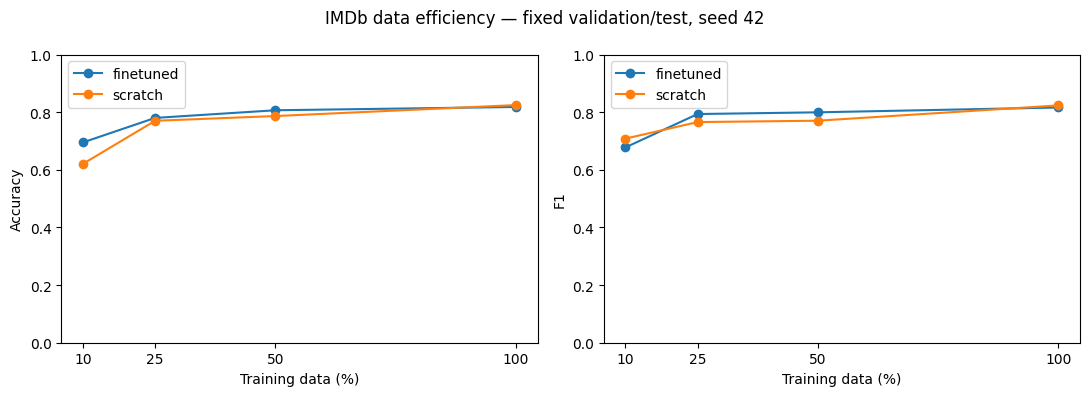

In [9]:
efficiency_rows = []
for fraction in [.10, .25, .50, 1.]:
    for mode in ['scratch', 'finetuned']:
        run = experiment.run(mode, fraction=fraction)
        efficiency_rows.append(run['row'])
efficiency_table = pd.DataFrame(efficiency_rows)
from IPython.display import Markdown
for mode, label in [('finetuned', 'Pretrained Transformer'), ('scratch', 'Transformer from scratch')]:
    display(Markdown('**' + label + '**'))
    data_table = efficiency_table.loc[efficiency_table['Mode'].eq(mode)].copy()
    data_table['Training data'] = data_table['Train fraction'].map(lambda fraction: f'{fraction:.0%}')
    display(data_table[['Training data', 'Accuracy', 'F1']].reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metric, ax in zip(['Accuracy', 'F1'], axes):
    for mode, group in efficiency_table.groupby('Mode'):
        ax.plot(group['Train fraction']*100, group[metric], marker='o', label=mode)
    ax.set(xlabel='Training data (%)', ylabel=metric, xticks=[10, 25, 50, 100], ylim=(0, 1))
    ax.legend()
fig.suptitle('IMDb data efficiency — fixed validation/test, seed 42')
plt.tight_layout()
fig.savefig(LAB_DIR/'data_efficiency.png', dpi=160, bbox_inches='tight')
plt.show()

**Pretraining có giúp sử dụng dữ liệu downstream hiệu quả hơn không?** 

Trong toàn bộ 4 mức dữ liệu, fine-tuned có F1 cao hơn scratch ở 2/4 mức. Tại 10%, chênh lệch F1 là -0.0306. Khi giảm 100% xuống 10%, F1 scratch giảm 0.1152, fine-tuned giảm 0.1386 (giá trị âm nghĩa là tăng).

Đường cong cho thấy lợi thế phụ thuộc mức dữ liệu; không thể kết luận pretrained luôn tốt hơn từ một điểm riêng lẻ. Theo Accuracy, fine-tuned cao hơn ở 3/4 mức; mức giảm 100%→10% là 0.2040 với scratch và 0.1230 với fine-tuned. 

Ở 10%, scratch có Precision/Recall 0.5756/0.9201, fine-tuned 0.7194/0.6404. Accuracy và F1 lớp positive có thể xếp hạng khác nhau do cách đánh đổi hai loại lỗi; F1 positive không phải macro-F1. Hai biểu đồ thể hiện những khía cạnh khác nhau của kết quả phân loại. Các đường cong chỉ có một seed; số bước cập nhật cũng giảm cùng kích thước subset.

#### 17. Experiment 4 — Maximum Sequence Length

Fine-tuning riêng ở T=64/128/256; cấu hình T=128 dùng lại. 

Attention eager của encoder tạo ma trận T×T; tăng 128→256 làm số phần tử mỗi head tăng 4 lần. Tổng RSS không nhất thiết tăng đúng 4 lần vì còn weights, optimizer, FFN, thư viện và memory reuse.

Cột `GPU/CPU memory` trong bảng là CPU RSS peak lấy mẫu, đơn vị MiB.


In [10]:
length_rows = [experiment.run('finetuned', length=length)['row'] for length in [64, 128, 256]]
length_table = pd.DataFrame(length_rows)
length_report = length_table[['Max length', 'Accuracy', 'F1', 'Training time (s)',
                             'CPU RSS peak sampled (MiB)']].rename(columns={
    'Training time (s)': 'Training time',
    'CPU RSS peak sampled (MiB)': 'GPU/CPU memory'
})
display(length_report)

**Tăng sequence length luôn làm model tốt hơn không?** 

Không có bảo đảm như vậy. Ở lần chạy này, F1 tại T=64/128/256 là 0.7596, 0.8162, 0.8549. Từ 128 lên 256, F1 đổi +0.0387, trong khi thời gian tăng 2.43 lần.

T lớn giữ thêm context nhưng cũng thêm chi phí và nội dung không liên quan. Với eager attention, số phần tử mỗi head tăng theo T²; RSS toàn process chịu thêm ảnh hưởng cache/allocator nên không dùng bảng này để nói bộ nhớ riêng model tăng đúng 4 lần. Nếu chọn T để triển khai cần dùng validation và ngân sách; bảng test ở đây chỉ báo cáo thí nghiệm, không dùng để chọn lại model application.


#### 18. Experiment 5 — Domain Shift

Train trên IMDb; đánh giá **cùng model fine-tuned T=128**, cùng tokenizer và ngưỡng argmax trên IMDb test và Amazon product-review sentences từ [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences) (Kotzias, 2015, CC BY 4.0). Nhãn cùng nghĩa 0=negative, 1=positive; không dùng Amazon để training hay chọn model.

Nguồn Amazon ban đầu có 1.000 câu; loại trùng theo lowercase, câu có nhãn mâu thuẫn và câu trùng chính xác với các split IMDb dùng trong bài. Ngoài domain, hai tập còn khác độ dài và cách tuyển chọn câu; so sánh phản ánh cả khác biệt domain/style, không tách riêng một nguyên nhân.

In [11]:
domain_result = experiment.domain_test(finetuned)
domain_table = pd.DataFrame([{'Domain': 'IMDb test', 'Samples': len(finetuned['y']),
                              **{m: finetuned['row'][m] for m in ['Accuracy', 'Precision', 'Recall', 'F1']}}, domain_result])
display(domain_table)

,Domain,Samples,Accuracy,Precision,Recall,F1,Raw samples,Removed duplicates/conflicts/overlap
0,IMDb test,2000,0.818000,0.825332,0.807193,0.816162,NaN,NaN
1,Amazon products (UCI),987,0.774063,0.728669,0.869654,0.792943,1000.0,13.0


**Pretrained model có nghĩa là model đã “hiểu mọi domain” không?** 

Không. Cùng checkpoint fine-tuned trên IMDb đạt Accuracy/F1 0.8180/0.8162 trên IMDb test và 0.7741/0.7929 trên 987 câu Amazon sau làm sạch (13 câu bị loại khỏi 1.000 câu gốc).

- **Observation:** F1 Amazon thấp hơn IMDb, chênh -0.0232. 
- **Evidence:** cùng model/tokenizer/ngưỡng, hai tập test có nhãn sentiment tương ứng nhưng khác domain/style. 
- **Interpretation:** Sự giảm phù hợp với khả năng model chưa chuyển được mọi đặc trưng sentiment từ phim sang sản phẩm. Chênh lệch không tách riêng domain khỏi độ dài, cách chọn mẫu và cách gán nhãn. Không thể khẳng định pretrained bao phủ mọi domain hoặc đo chính xác một nguyên nhân chỉ bằng hai score này.

#### 19. Application — Sentiment Classification

Dùng tiếp fine-tuned BERT-Tiny T=128 đã cố định, không đổi sang model có test score cao nhất. Báo cáo đủ Accuracy, Precision, Recall, F1 trên IMDb; confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán. Các câu tự nhập bên dưới chỉ minh họa inference, không phải tập test mới.

,Accuracy,Precision,Recall,F1
0,0.818,0.825332,0.807193,0.816162


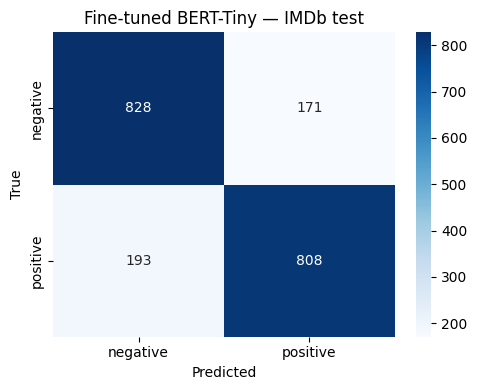

,Text,Predicted,Label,P(positive),Confidence
0,I really enjoyed this movie.,1,positive,0.985132,0.985132
1,I did not enjoy this movie at all.,1,positive,0.891294,0.891294
2,"The beginning was boring, but the ending was e...",0,negative,0.485631,0.514369


In [12]:
from sklearn.metrics import confusion_matrix
display(pd.DataFrame([{m: finetuned['row'][m] for m in ['Accuracy', 'Precision', 'Recall', 'F1']}]))
cm = confusion_matrix(finetuned['y'], finetuned['pred'], labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'],
            yticklabels=['negative', 'positive'], ax=ax)
ax.set(xlabel='Predicted', ylabel='True', title='Fine-tuned BERT-Tiny — IMDb test')
plt.tight_layout()
fig.savefig(LAB_DIR/'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
application_model = experiment.load_model(finetuned)
application_rows = [pc.predict_text(application_model, tokenizer, text) for text in [
    'I really enjoyed this movie.', 'I did not enjoy this movie at all.',
    'The beginning was boring, but the ending was excellent and I loved the movie overall.']]
display(pd.DataFrame(application_rows).drop(columns='Visible text'))
experiment.analysis['confusion_matrix'] = cm
experiment.analysis['application'] = application_rows
experiment.save()

Confusion matrix cho TN=828, FP=171, FN=193, TP=808. Accuracy=0.8180, Precision=0.8253, Recall=0.8072, F1=0.8162. Precision phản ánh độ đúng trong những review được gọi positive; Recall phản ánh phần positive thật được tìm thấy. Vì hai loại lỗi có ý nghĩa khác nhau, accuracy riêng lẻ không đủ mô tả model.

Các xác suất trong ví dụ nhập tay là softmax chưa calibration. Mục 20–21 kiểm tra trực tiếp các lỗi và mức tự tin trên test.

#### 20. Error Analysis


In [13]:
y, pred, prob = finetuned['y'], finetuned['pred'], finetuned['prob']
confidence = prob.max(1)
rng = np.random.default_rng(pc.SEED)
fp = rng.choice(np.flatnonzero((y==0)&(pred==1)), 3, replace=False)
fn = rng.choice(np.flatnonzero((y==1)&(pred==0)), 3, replace=False)
selected = set(fp.tolist()+fn.tolist())
confident_errors = [i for i in np.argsort(-confidence, kind='stable') if y[i]!=pred[i] and i not in selected][:2]
error_examples = []
for prefix, indices in [('FP', fp), ('FN', fn), ('HC', confident_errors)]:
    for number, index in enumerate(indices, 1):
        index = int(index)
        record = experiment.data['test'].iloc[index]
        full_ids = tokenizer(record.text, add_special_tokens=False)['input_ids']
        encoded = tokenizer(record.text, truncation=True, max_length=pc.BASE_LENGTH)
        actual_tokens = tokenizer.convert_ids_to_tokens(encoded['input_ids'])
        error_examples.append({'ID': f'{prefix}{number}', 'test_index': index, 'source_row': int(record.source_row),
                               'Text': record.text, 'True': int(y[index]), 'Pred': int(pred[index]),
                               'Confidence': float(confidence[index]), 'P(positive)': float(prob[index,1]),
                               'Full content tokens': len(full_ids), 'Seen content tokens': len(encoded['input_ids'])-2,
                               'UNK seen': actual_tokens.count('[UNK]'),
                               'Continuation pieces seen': sum(t.startswith('##') for t in actual_tokens),
                               'Visible text': tokenizer.decode(encoded['input_ids'], skip_special_tokens=True)})
error_annotations = {
    'FP1': ('Mixed sentiment; context/truncation', 'Đoạn đầu có lời khen, phần chê và kết luận negative nằm ngoài input.'),
    'FP2': ('Quoted sentiment; câu hỏi tu từ; context/truncation', 'Nhầm lời khen được tác giả dẫn lại để phản bác với quan điểm của chính tác giả.'),
    'FP3': ('Giả định; mixed sentiment; long context/truncation', 'Đọc lời khen giả định như đánh giá hiện tại và mất phần kết luận chê.'),
    'FN1': ('Negation; giả định; sentiment lẫn lộn', 'Chưa tổng hợp được phủ định của embarrassing với các lời khen trực tiếp.'),
    'FN2': ('Ambiguous sentiment; domain-specific expression', 'Review phim cult trộn sự khó chịu, thích thú và phê bình; nhãn nhị phân không diễn đạt hết sắc thái.'),
    'FN3': ('Nghi ngờ label ambiguity/noise; comparison', 'Nhãn positive có vẻ không khớp lời chê trong text; cần đối chiếu rating/nguồn gốc.'),
    'HC1': ('Nghi ngờ label ambiguity/noise; mixed sentiment', 'Text chủ yếu chê nhưng nhãn positive; lỗi benchmark có thể liên quan chất lượng nhãn.'),
    'HC2': ('Nghi ngờ label ambiguity/noise', 'Nhãn negative không khớp chuỗi lời khen trực tiếp; chưa có bằng chứng sarcasm.'),
}
error_table = pd.DataFrame(error_examples)
error_table['Text'] = error_table['ID'] + ': ' + error_table['Text'].str.slice(0, 160) + '…'
error_table['True'] = error_table['True'].map({0: 'negative', 1: 'positive'})
error_table['Pred'] = error_table['Pred'].map({0: 'negative', 1: 'positive'})
error_table['Error type'] = error_table['ID'].map(lambda key: error_annotations[key][0])
error_table['Hypothesis'] = error_table['ID'].map(lambda key: error_annotations[key][1])
display(error_table[['Text', 'True', 'Pred', 'Confidence', 'Error type', 'Hypothesis']])
for example in error_examples:
    print(example['ID'], '| visible:', example['Visible text'])
experiment.analysis['errors'] = error_examples
experiment.save()

FP1 | visible: i didn ' t want to write this movie off on the reviews and critics in the western world, i mean how wrong have they been about asian cinema that has now become a staple diet of the hollywood remake monster? plus jet l is pretty damn cool, and he ' s made some interesting movies in asia. so with an open mind i was surprisingly averaged out by this movie. there are good points. the story is very clever, using m - theory as a base to bring forward the plot that there are multiple universes each with their own versions of worlds, and most likely you. each time one of you is destroyed the
FP2 | visible: why is it that every time i mention this movie to somebody, i have to hear 10 minutes of praise about it. i have come to the conclusion that any movie that has a twist upon a twist is deemed " genius " by anyone who watches it. is that really what film has become? or is it that any time someone says " wow, that is so cool " everybody has to agree with them and has no opinion o

,Text,True,Pred,Confidence,Error type,Hypothesis
0,FP1: I didn't want to write this movie off on ...,negative,positive,0.577726,Mixed sentiment; context/truncation,"Đoạn đầu có lời khen, phần chê và kết luận neg..."
1,FP2: Why is it that every time I mention this ...,negative,positive,0.673986,Quoted sentiment; câu hỏi tu từ; context/trunc...,Nhầm lời khen được tác giả dẫn lại để phản bác...
2,"FP3: First of all, this film is GLACIALLY slow...",negative,positive,0.645337,Giả định; mixed sentiment; long context/trunca...,Đọc lời khen giả định như đánh giá hiện tại và...
3,FN1: What can you possibly say? This is the un...,positive,negative,0.544644,Negation; giả định; sentiment lẫn lộn,Chưa tổng hợp được phủ định của embarrassing v...
4,"FN2: A very strange, disturbing but intriguing...",positive,negative,0.887752,Ambiguous sentiment; domain-specific expression,"Review phim cult trộn sự khó chịu, thích thú v..."
5,"FN3: I know it was supposed to be a long walk,...",positive,negative,0.971935,Nghi ngờ label ambiguity/noise; comparison,Nhãn positive có vẻ không khớp lời chê trong t...
6,HC1: after seeing this film for the 3rd time n...,positive,negative,0.991194,Nghi ngờ label ambiguity/noise; mixed sentiment,Text chủ yếu chê nhưng nhãn positive; lỗi benc...
7,HC2: this is a great movie. I love the series ...,negative,positive,0.990787,Nghi ngờ label ambiguity/noise,Nhãn negative không khớp chuỗi lời khen trực t...


#### 21. Confidence Analysis

`probabilities = softmax(logits)`; `confidence = max(probabilities)`. Chia trước khi xem kết quả: **Low [0.50,0.70), Medium [0.70,0.90), High [0.90,1.00]**. Tính số mẫu, mean confidence, accuracy và số sai trong mỗi nhóm; nhóm rỗng không được diễn giải là accuracy 0.

,Group,Samples,Mean confidence,Accuracy,Errors
0,Low,422,0.604701,0.580569,177
1,Medium,631,0.811827,0.779715,139
2,High,947,0.960531,0.949314,48


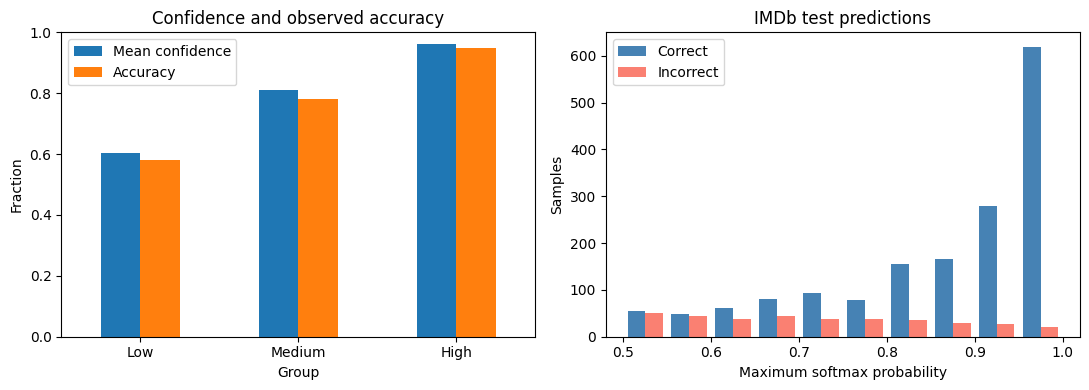

In [14]:
confidence_rows = []
for name, lower, upper in [('Low', .5, .7), ('Medium', .7, .9), ('High', .9, 1.000001)]:
    mask = (confidence>=lower)&(confidence<upper)
    confidence_rows.append({'Group': name, 'Samples': int(mask.sum()),
                            'Mean confidence': float(confidence[mask].mean()) if mask.any() else np.nan,
                            'Accuracy': float((y[mask]==pred[mask]).mean()) if mask.any() else np.nan,
                            'Errors': int((y[mask]!=pred[mask]).sum())})
confidence_table = pd.DataFrame(confidence_rows)
display(confidence_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
confidence_table.set_index('Group')[['Mean confidence', 'Accuracy']].plot.bar(ax=axes[0], rot=0)
axes[0].set(ylim=(0, 1), ylabel='Fraction', title='Confidence and observed accuracy')
axes[1].hist([confidence[y==pred], confidence[y!=pred]], bins=np.linspace(.5, 1, 11),
             label=['Correct', 'Incorrect'], color=['steelblue', 'salmon'])
axes[1].set(xlabel='Maximum softmax probability', ylabel='Samples', title='IMDb test predictions')
axes[1].legend()
plt.tight_layout()
fig.savefig(LAB_DIR/'confidence_analysis.png', dpi=160, bbox_inches='tight')
plt.show()
experiment.analysis['confidence'] = confidence_rows
experiment.save()

**Confidence cao có đồng nghĩa prediction đúng không?** 

Không. Nhóm High có 947 mẫu, trong đó 48 mẫu sai; accuracy 0.9493, mean confidence 0.9605. HC1/HC2 ở mục 20 là hai ví dụ sai có confidence cao được lấy từ chính test.

Đúng/sai ở đây được tính so với nhãn dataset. HC1/HC2 có dấu hiệu nhãn mâu thuẫn sắc thái văn bản, nên hai mẫu đó không tự chứng minh model hiểu sai sentiment; chất lượng nhãn cũng ảnh hưởng việc đánh giá confidence.

Confidence là giá trị softmax, không phải xác suất đã được bảo đảm đúng trên mọi phân phối dữ liệu. Sai khác giữa mean confidence và accuracy theo nhóm là một mô tả sơ bộ về calibration; ba nhóm rộng và một test set chưa đủ kết luận calibration cho mọi ngưỡng/domain. Temperature và ngưỡng dự đoán được giữ nguyên trong quá trình đánh giá test.

#### 22. Ablation / Analysis

Chọn **A — Frozen vs Fine-tuned** làm ablation chính; dùng lại mục 15. Cùng checkpoint khởi tạo encoder, head, split, tokenizer, T=128, batch, optimizer, LR và epochs. Thay chính là encoder có được cập nhật hay không; encoder frozen ở eval còn encoder fine-tuned có dropout trong training. Đây là khác biệt đi kèm của chế độ feature extraction.

Các mục 14, 16, 17 đã cung cấp thêm các đối chiếu mà không train lại cùng cấu hình. Phần nhận xét đối chiếu kết quả với các dự đoán ban đầu.

**Observation:** Frozen F1=0.6793; fine-tuned F1=0.8162, chênh **+0.1369**.

**Evidence:** hai run mục 15 cùng dữ liệu, checkpoint đầu vào, head, T và lịch tối ưu; trainable parameters lần lượt 258 và 4,369,666. Thời gian là 41.45s và 150.26s.

**Interpretation:** Cập nhật representation theo sentiment có lợi trong thiết lập này; head tuyến tính trên đặc trưng cố định chưa đạt cùng F1. Chưa đo nhiều seed hoặc tối ưu LR riêng cho frozen, nên không coi chênh lệch là giới hạn tốt nhất của mỗi chế độ. Catastrophic forgetting là một rủi ro của fine-tuning, nhưng bài chưa đo tác vụ/pretraining loss trước–sau để xác nhận nó xảy ra.

#### 23. Reproducibility

Một kết quả NLP gồm cấu hình, dữ liệu, cách chọn model và tài nguyên, không chỉ một con số accuracy. Thông tin mỗi run được lưu trong `results.csv`; các hash xác định dữ liệu/split cụ thể. Thời gian và RSS có thể khác khi chạy lại trên máy khác.

In [15]:
repro_rows = []
for run in experiment.runs.values():
    row = run['row']
    repro_rows.append({key: row[key] for key in ['Run', 'Train samples', 'Validation samples', 'Test samples',
        'Max length', 'Batch size', 'Learning rate', 'Epochs', 'Optimizer', 'Seed', 'Best epoch', 'Training time (s)']})
display(pd.DataFrame(repro_rows))
print('Model:', pc.MODEL_ID, pc.REVISION)
print('Tokenizer:', type(tokenizer).__name__, 'uncased WordPiece, vocab=', tokenizer.vocab_size)
print('Dataset/splits:', experiment.data_info)
print('Hardware:', experiment.hardware)

Model: prajjwal1/bert-tiny 6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837
Tokenizer: BertTokenizer uncased WordPiece, vocab= 30522
Dataset/splits: {'dataset': 'IMDb Dataset.csv', 'raw_samples': 50000, 'clean_samples': 49578, 'removed_duplicates': 422, 'dataset_sha256': '6f1314f123ac922d7d0f2bd5bd17f1734e167d90b2256c34963228bc63f6a4cb', 'split_hashes': {'train': '66b880f2466d190a8e33929e0b8b4e02510de76d7f901701b25877f39106ec6f', 'validation': '01e3d4e28594a5b3dc3189f1bbd405ce4e21d73d55ce6de039df477e6c3bc0ca', 'test': 'f6e87bfd76e48bb32e9eca90bd16c6090a88959198a49f499e87d87d5ddec492'}}
Hardware: {'device': 'cpu', 'processor': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD', 'logical_cpus': 16, 'torch_threads': 4, 'torch': '2.11.0+cpu', 'transformers': '5.22.2', 'python': '3.12.7'}


,Run,Train samples,Validation samples,Test samples,Max length,Batch size,Learning rate,Epochs,Optimizer,Seed,Best epoch,Training time (s)
0,scratch-n100-T128,10000,2000,2000,128,64,0.0002,3,AdamW,42,2,143.781211
1,finetuned-n100-T128,10000,2000,2000,128,64,0.0002,3,AdamW,42,2,150.255969
2,frozen-n100-T128,10000,2000,2000,128,64,0.0002,3,AdamW,42,3,41.450696
3,scratch-n10-T128,1000,2000,2000,128,64,0.0002,3,AdamW,42,2,20.901310
4,finetuned-n10-T128,1000,2000,2000,128,64,0.0002,3,AdamW,42,2,19.791346
5,scratch-n25-T128,2500,2000,2000,128,64,0.0002,3,AdamW,42,3,41.924996
6,finetuned-n25-T128,2500,2000,2000,128,64,0.0002,3,AdamW,42,2,40.929830
7,scratch-n50-T128,5000,2000,2000,128,64,0.0002,3,AdamW,42,2,77.657911
8,finetuned-n50-T128,5000,2000,2000,128,64,0.0002,3,AdamW,42,2,80.940687
9,finetuned-n100-T64,10000,2000,2000,64,64,0.0002,3,AdamW,42,1,69.872084


| Trường | Cấu hình |
|---|---|
| Model | prajjwal1/bert-tiny; 2 layers, hidden 128, 2 heads, FFN 512; 4,369,666 parameters; revision `6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837` |
| Tokenizer | BertTokenizerFast, uncased WordPiece, vocabulary 30.522, cùng revision; right padding/truncation |
| Dataset | IMDb 50.000 → 49.578 sau clean/dedup; Amazon UCI 987 câu chỉ để test khác miền |
| Train split | 70% của IMDb đã clean; subset cơ sở 10.000 như LAB 07; các subset lồng nhau 1.000/2.500/5.000/10.000 |
| Validation split | 15% rồi lấy 2.000; giữ cố định, dùng chọn checkpoint min validation loss |
| Test split | 15% còn lại rồi lấy 2.000; giữ cố định, không tối ưu hyperparameters trên test |
| Max sequence length | Cơ sở 128; experiment 64/128/256; bao gồm [CLS]/[SEP] |
| Batch size | 64; batch cuối có thể nhỏ hơn |
| Learning rate | 0.0002 cho mọi tham số trainable và mọi mode; không scheduler |
| Epochs | 3; chọn checkpoint tốt nhất, không mặc định lấy epoch cuối |
| Optimizer | AdamW, weight_decay=0.01; gradient clipping norm=1.0 |
| Random seed | 42 cho split/subset/training; head dùng seed 43 cố định ở mọi run |
| Hardware | CPU, AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD, 16 logical CPUs; PyTorch dùng 4 threads; không GPU |
| Software | Python 3.12.7; torch 2.11.0+cpu; transformers 5.22.2; tokenizers 0.23.3; huggingface-hub 2.4.0; safetensors 0.8.0; numpy 1.26.4; pandas 2.2.2; scikit-learn 1.5.2; psutil 6.1.0 |
| Training time | Bảng bên dưới; train + validation + copy best state, không download/tokenization/test/pretraining |

| Run | Training time (s) |
| --- | --- |
| scratch-n100-T128 | 143.7812 |
| finetuned-n100-T128 | 150.2560 |
| frozen-n100-T128 | 41.4507 |
| scratch-n10-T128 | 20.9013 |
| finetuned-n10-T128 | 19.7913 |
| scratch-n25-T128 | 41.9250 |
| finetuned-n25-T128 | 40.9298 |
| scratch-n50-T128 | 77.6579 |
| finetuned-n50-T128 | 80.9407 |
| finetuned-n100-T64 | 69.8721 |
| finetuned-n100-T256 | 365.7110 |

IMDb SHA256: `6f1314f123ac922d7d0f2bd5bd17f1734e167d90b2256c34963228bc63f6a4cb`. Hash từng split/subset có trong output và CSV. RSS là bộ nhớ toàn process lấy mẫu 20 ms, không phải peak GPU hoặc bộ nhớ riêng model. Checkpoint/cache nằm trong `.lab08_cache/` ngoài thư mục nộp bài. Run All huấn luyện lại; các nhận xét Markdown là báo cáo của lần chạy được lưu.


#### 28. Error Analysis — câu hỏi bắt buộc

Các câu trả lời trình bày theo **observation → evidence → interpretation**, gắn nhận định với số liệu và điều kiện thí nghiệm.

##### Q1. Model nào hưởng lợi nhiều hơn khi training data ít?

**Observation:** Ở 10%, scratch Accuracy/F1=0.6205/0.7082, fine-tuned=0.6950/0.6776. 

**Evidence:** fine-tuned có F1 cao hơn scratch ở 2/4 mức và Accuracy cao hơn ở 3/4 mức dữ liệu trong mục 16. Giảm F1 100%→10% là 0.1152 với scratch và 0.1386 với fine-tuned; giảm Accuracy tương ứng 0.2040 và 0.1230. 

**Interpretation:** Ở 10%, scratch có F1 positive cao hơn; pretrained lại có accuracy cao hơn và giữ Accuracy tốt hơn khi giảm dữ liệu, nên lợi thế phụ thuộc metric và cách đánh đổi precision/recall. Mức score khi ít nhãn và mức giảm score là hai tiêu chí khác nhau; kết quả ở đây chỉ hỗ trợ một phần dự đoán ban đầu.

##### Q2. Nếu pretrained tốt hơn from-scratch, điều đó chứng minh điều gì?

**Observation:** run 100% có F1 pretrained=0.8162, scratch=0.8234. 

**Evidence:** cùng kiến trúc/tokenizer/split/LR/epochs, khác khởi tạo encoder. 

**Interpretation:** nếu pretrained tốt hơn, đó là bằng chứng khởi tạo đã học hữu ích cho tác vụ và lịch train đang xét. Không chứng minh hiểu ngôn ngữ toàn diện, không đảm bảo mọi domain, không chứng minh scratch với thêm dữ liệu/compute không thể đạt được.

##### Q3. Nếu frozen gần bằng fine-tuned, điều đó có ý nghĩa gì?

**Observation:** kết quả thực tế frozen=0.6793, fine-tuned=0.8162, chênh +0.1369. 

**Evidence cần cho giả thiết gần bằng:** score gần nhau qua nhiều seed, cùng dữ liệu và lịch đánh giá; không chỉ hai số làm tròn. 

**Interpretation:** nếu được xác nhận, representation cố định đã đủ hữu ích cho head phân loại; có thể ưu tiên frozen để giảm chi phí/update và rủi ro overfit. Không suy ra encoder luôn không cần thích nghi.

##### Q4. Nếu fine-tuning tốt hơn frozen rất nhiều, điều đó gợi ý gì?

**Observation:** chênh F1 đo được là +0.1369. 

**Evidence:** số liệu frozen/fine-tuned mục 15 cùng cấu hình chính. 

**Interpretation:** chênh lệch lớn gợi ý representation cần thích nghi với tín hiệu sentiment, hoặc head tuyến tính trên representation hiện tại chưa tách tốt các lớp. Cũng phải xét chất lượng tối ưu head, pooling và độ biến thiên seed; chưa thể quy duy nhất cho “hiểu ngôn ngữ tốt hơn”.

##### Q5. Nếu performance giảm mạnh trên domain khác, nguyên nhân có thể là gì?

**Observation:** IMDb F1=0.8162, Amazon F1=0.7929; chênh -0.0232. 

**Evidence:** cùng model được test trên review phim dài và câu review sản phẩm ngắn, tuyển chọn/gán nhãn khác nhau. 

**Interpretation:** nếu giảm mạnh, có thể do cách dùng từ, phân phối input/label, độ dài, thuật ngữ, tokenizer hoặc over-specialization khi fine-tune. Mức giảm F1 quan sát được là 0.0232; một tập dữ liệu ngoài miền chưa đại diện cho mọi domain.

##### Q6. Nếu tăng sequence length mà performance gần như không đổi, thời gian tăng mạnh, có nên tiếp tục tăng?

**Observation:** T=128→256 có ΔF1=+0.0387, thời gian 150.26→365.71s. 

**Evidence:** bảng length mục 17 giữ cùng model/data/epochs. 

**Interpretation:** trong tình huống gain nhỏ nhưng chi phí lớn, thường nên dừng ở độ dài ngắn hơn đáp ứng mục tiêu; chỉ tăng tiếp nếu validation và phân tích lỗi cho thấy context bị cắt là vấn đề đáng giải quyết trong ngân sách. Chia đoạn hoặc chọn đoạn là những hướng thử nghiệm tiếp theo; hiệu quả của chúng chưa được đánh giá trong bài.



In [16]:
experiment.save()
display(pd.read_csv(LAB_DIR/'results.csv')[['Run', 'Domain', 'Accuracy', 'Precision', 'Recall', 'F1', 'Training time (s)']])
print('Saved results.csv; all training configurations and the Amazon evaluation are included.')

Saved results.csv; all training configurations and the Amazon evaluation are included.


,Run,Domain,Accuracy,Precision,Recall,F1,Training time (s)
0,scratch-n100-T128,IMDb,0.824500,0.829615,0.817183,0.823352,143.781211
1,finetuned-n100-T128,IMDb,0.818000,0.825332,0.807193,0.816162,150.255969
2,frozen-n100-T128,IMDb,0.687000,0.697161,0.662338,0.679303,41.450696
3,scratch-n10-T128,IMDb,0.620500,0.575625,0.920080,0.708189,20.901310
4,finetuned-n10-T128,IMDb,0.695000,0.719416,0.640360,0.677590,19.791346
5,scratch-n25-T128,IMDb,0.770000,0.781478,0.750250,0.765545,41.924996
6,finetuned-n25-T128,IMDb,0.780000,0.748450,0.844156,0.793427,40.929830
7,scratch-n50-T128,IMDb,0.786500,0.834499,0.715285,0.770307,77.657911
8,finetuned-n50-T128,IMDb,0.806500,0.830819,0.770230,0.799378,80.940687
9,finetuned-n100-T64,IMDb,0.750000,0.732159,0.789211,0.759615,69.872084
